<a href="https://colab.research.google.com/github/LexDomingues/Facial-recognition/blob/main/Facial_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 6.4 MB/s eta 0:00:00


In [4]:
import os
from ultralytics import YOLO
import yaml
import torch
import matplotlib.pyplot as plt
import random
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras import layers, models
import numpy as np
from PIL import Image
import cv2
from pathlib import Path
from collections import Counter

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [24]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fareselmenshawii/face-detection-dataset")

print("Path to dataset files:", path)

100%|██████████| 4.43G/4.43G [03:44<00:00, 21.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/fareselmenshawii/face-detection-dataset/versions/3


In [25]:
root_dataset = "/root/.cache/kagglehub/datasets/fareselmenshawii/face-detection-dataset/versions/3"

config = {
    "path": root_dataset,
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": ["rosto"]
}

root_config = os.path.join(root_dataset, "data_colab.yaml")

with open(root_config, "w", encoding="utf-8") as arquivo:
    yaml.safe_dump(config, arquivo, sort_keys=False, allow_unicode=True)

print("Configuration created on:", root_config)


Configuration created on: /root/.cache/kagglehub/datasets/fareselmenshawii/face-detection-dataset/versions/3/data_colab.yaml


In [26]:
print("GPU available:", torch.cuda.is_available())

GPU available: True


In [ ]:
model = YOLO("yolo11n.pt")

results = model.train(
    data=root_config,
    epochs=30,
    imgsz=640,
    batch=16,
    patience=5,
    project="/content/drive/MyDrive/Project_Faces",
    name="face_detector_kaggle",
    plots=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/.cache/kagglehub/datasets/fareselmenshawii/face-detection-dataset/versions/3/data_colab.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0

In [27]:
model_root = "/content/drive/MyDrive/Project_Faces/face_detector_kaggle/weights/best.pt"

model = YOLO(model_root)

print("Model loaded!")

Model loaded!



image 1/1 /content/images.jpg: 640x448 1 rosto, 31.5ms
Speed: 18.6ms preprocess, 31.5ms inference, 12.3ms postprocess per image at shape (1, 3, 640, 448)


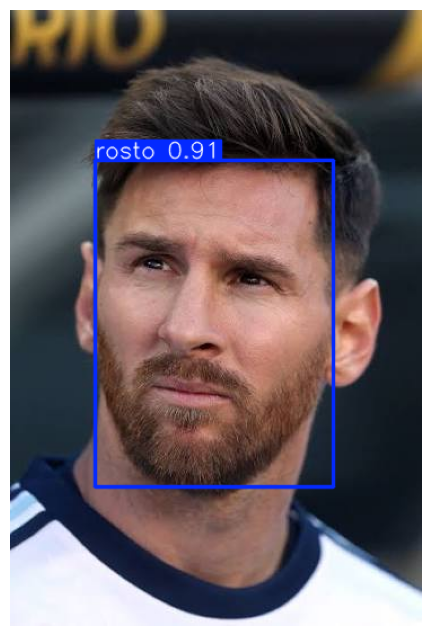

In [29]:
image_root = "images.jpg"

results = model.predict(
    source=image_root,
    conf=0.5
)

image_detected = results[0].plot()

plt.figure(figsize=(10, 8))
plt.imshow(image_detected[:, :, ::-1])
plt.axis("off")
plt.show()

In [5]:
source_path = "/content/drive/MyDrive/Ronaldo x Messi Detection.v1i.yolov11"

destination_path = "/content/drive/MyDrive/Project_Faces/faces_new_dataset"

divisions = {
    "train": "train",
    "valid": "valid",
    "test": "test"
}

classes = {
    "0": "Messi",
    "1": "CR7"
}

extensions = {".jpg", ".jpeg", ".png", ".webp"}

for division, output_folder in divisions.items():
    images_path = os.path.join(source_path, division, "images")
    labels_path = os.path.join(source_path, division, "labels")

    for player in classes.values():
        os.makedirs(
            os.path.join(destination_path, output_folder, player),
            exist_ok=True
        )

    amount = Counter()

    for label_file in os.listdir(labels_path):
        if not label_file.endswith(".txt"):
            continue

        base_name = Path(label_file).stem

        image_root = None

        for ext in extensions:
            candidate = os.path.join(images_path, base_name + ext)
            if os.path.isfile(candidate):
                image_root = candidate
                break

        if image_root is None:
            continue

        image = cv2.imread(image_root)

        if image is None:
            continue

        height, width = image.shape[:2]

        txt_root = os.path.join(labels_path, label_file)

        with open(txt_root, "r") as f:
            lines = f.readlines()

        for line_index, line in enumerate(lines):
            values = line.split()

            if len(values) != 5 or values[0] not in classes:
                continue

            classe, cx, cy, bw, bh = values
            cx, cy, bw, bh = map(float, (cx, cy, bw, bh))

            x1 = max(0, int((cx - bw / 2) * width))
            y1 = max(0, int((cy - bh / 2) * height))
            x2 = min(width, int((cx + bw / 2) * width))
            y2 = min(height, int((cy + bh / 2) * height))

            face = image[y1:y2, x1:x2]

            if face.size == 0:
                continue

            player = classes[classe]
            output_name = f"{base_name}_{line_index}.jpg"

            destination = os.path.join(
                destination_path, output_folder, player, output_name
            )

            cv2.imwrite(destination, face)
            amount[player] += 1

    print(f"\n{division.upper()}:")
    print(dict(amount))

print("\nExtraction complete!")
print("Folder created:", destination_path)



TRAIN:
{'Messi': 540, 'CR7': 522}

VALID:
{'Messi': 122, 'CR7': 106}

TEST:
{'Messi': 111, 'CR7': 116}

Extraction complete!
Folder created: /content/drive/MyDrive/Project_Faces/faces_new_dataset


In [12]:
dataset_root = (
    "/content/drive/MyDrive/Project_Faces/faces_new_dataset"
)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 123

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(dataset_root, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

valid_ds = keras.utils.image_dataset_from_directory(
    os.path.join(dataset_root, "valid"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(dataset_root, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Order of classes:", train_ds.class_names)


Found 1062 files belonging to 2 classes.
Found 228 files belonging to 2 classes.
Found 227 files belonging to 2 classes.
Order of classes: ['CR7', 'Messi']


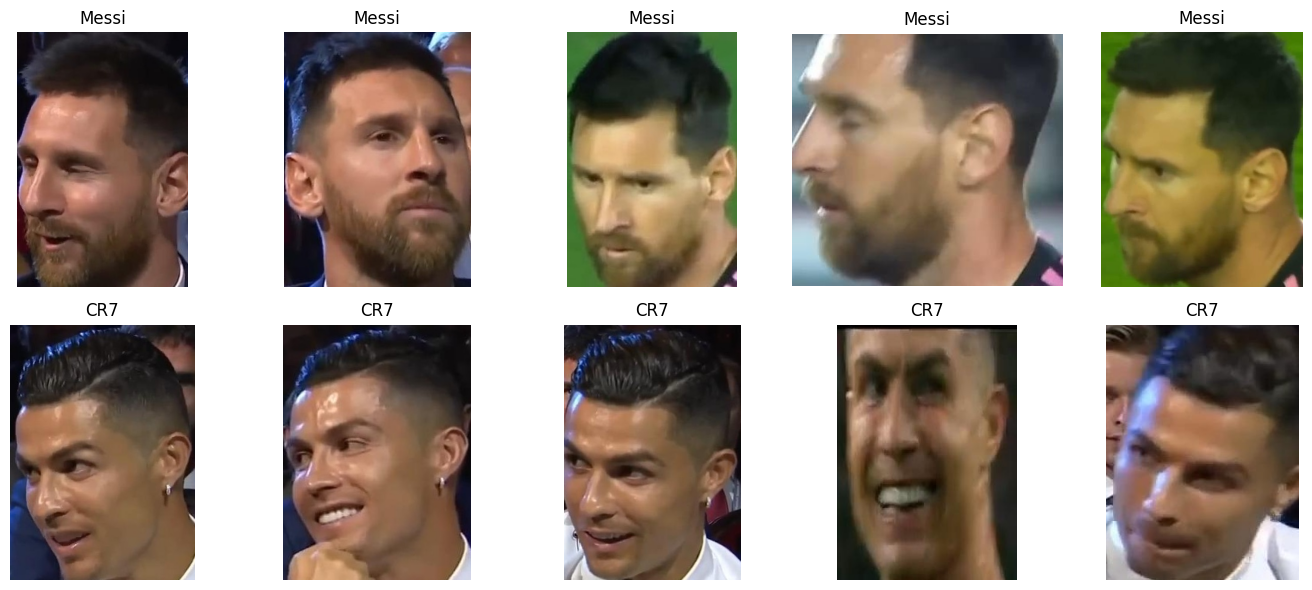

In [ ]:
path = "/content/drive/MyDrive/Project_Faces/faces_new_dataset/train"

random.seed(42)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for line, player in enumerate(["Messi", "CR7"]):
    player_path = os.path.join(path, player)
    files = [
        f for f in os.listdir(player_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    samples = random.sample(files, min(5, len(files)))

    for column, file in enumerate(samples):
        image = Image.open(
            os.path.join(player_path, file)
        ).convert("RGB")

        axes[line, column].imshow(image)
        axes[line, column].set_title(player)
        axes[line, column].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
new_cnn_mode = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Convolutional Block 1
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classificator
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])


new_cnn_mode.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


new_cnn_mode.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = new_cnn_mode.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)


Epoch 1/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.6789 - loss: 0.5791 - val_accuracy: 0.9035 - val_loss: 0.2535
Epoch 2/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.9275 - loss: 0.2190 - val_accuracy: 0.8816 - val_loss: 0.3068
Epoch 3/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9416 - loss: 0.1553 - val_accuracy: 0.9693 - val_loss: 0.0833
Epoch 4/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9605 - loss: 0.0907 - val_accuracy: 0.9868 - val_loss: 0.0507
Epoch 5/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.9802 - loss: 0.0698 - val_accuracy: 0.9868 - val_loss: 0.0345
Epoch 6/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9840 - loss: 0.0429 - val_accuracy: 0.9868 - val_loss: 0.0339
Epoch 7/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.9915 - loss: 0.0247 - val_accuracy: 0.9912 - val_loss: 0.0274
Epoch 8/30
34/34 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.9934 - loss: 0.0247 - val_accuracy: 0.9781 - val_loss:

In [ ]:
test_loss, test_accuracy = new_cnn_mode.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

new_cnn_mode.save(
    "/content/drive/MyDrive/Project_Faces/classificador_messi_cr7_cnn_do_zero.keras"
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 323ms/step - accuracy: 0.9824 - loss: 0.1535
Test loss: 0.1535
Test accuracy: 98.24%


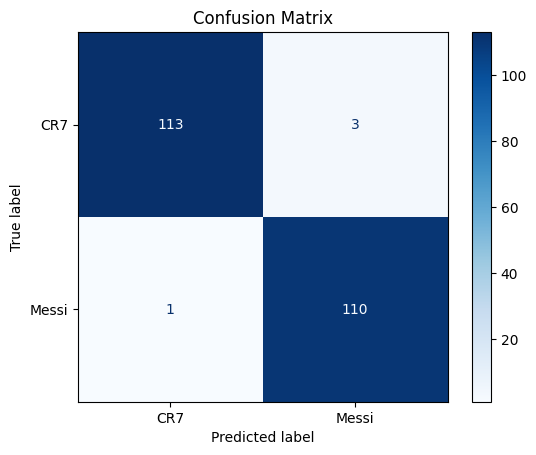

In [19]:
model_root = "/content/drive/MyDrive/Project_Faces/classificador_messi_cr7_cnn_do_zero.keras"
new_cnn_mode = keras.models.load_model(model_root)

y_real = np.concatenate([y.numpy().ravel() for x, y in test_ds])
y_pred = (new_cnn_mode.predict(test_ds, verbose=0).ravel() >= 0.5).astype(int)

matriz = confusion_matrix(y_real, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["CR7", "Messi"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix")
plt.show()


In [4]:
yolo_root = "/content/drive/MyDrive/Project_Faces/face_detector_kaggle/weights/best.pt"
cnn_root = "/content/drive/MyDrive/Project_Faces/classificador_messi_cr7_cnn_do_zero.keras"

model_yolo = YOLO(yolo_root)
model_cnn = tf.keras.models.load_model(cnn_root)

print("YOLO and CNN successfully loaded!")

YOLO and CNN successfully loaded!


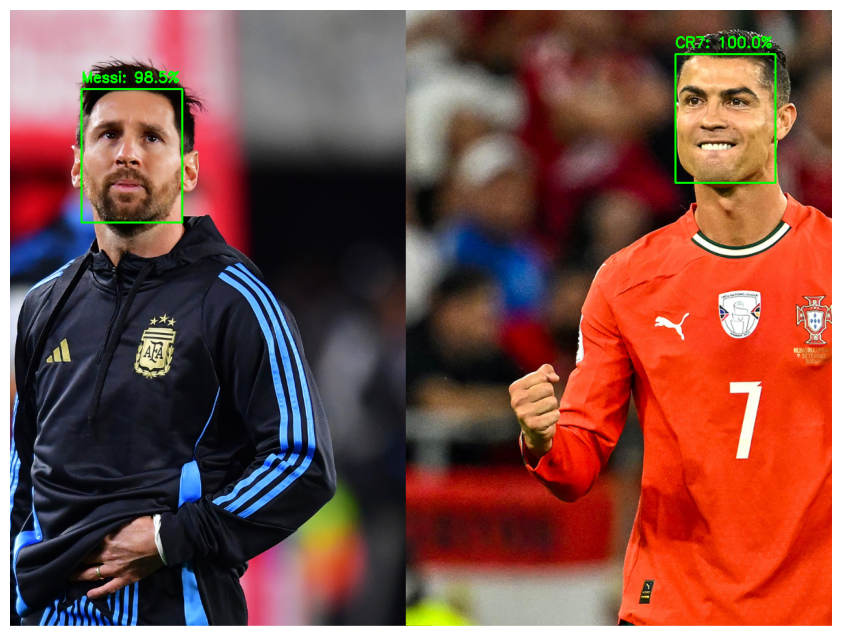

In [21]:
root = "messi_cristiano_ronaldo.webp"
image = cv2.cvtColor(
    cv2.imread(root),
    cv2.COLOR_BGR2RGB
)

result = model_yolo.predict(
    image,
    conf=0.25,
    verbose=False
)[0]

# Iterate through each detected face
for i, box in enumerate(result.boxes):

    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().numpy()
    )

    # Crop the face
    face = image[y1:y2, x1:x2]

    if face.size == 0:
        continue

    # Prepare the image for the CNN
    face = cv2.resize(face, (128, 128))
    face = face.astype("float32")

    # Add lot dimension
    input = np.expand_dims(face, axis=0)

    # The sigmoid output represents the probability for Mess
    prob_messi = float(
        model_cnn.predict(input, verbose=0)[0][0]
    )

    # Classify the face
    if prob_messi >= 0.5:
        name = "Messi"
        trust = prob_messi * 100
    else:
        name = "CR7"
        trust = (1 - prob_messi) * 100

    # Design the box and the classification
    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        image,
        f"{name}: {trust:.1f}%",
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()
